# P3 / 02: trading same-slot persistence (economic)

Protocol: [`001_claude_p3_intraday_periodicity_preregistration.md`](../../discussions/Intraday_Periodicity/001_claude_p3_intraday_periodicity_preregistration.md), section 5.

Signal: the stock's mean return in the same 30-minute slot over the previous 20 sessions (1, 5, 40 reported). Each interval, equal-weight long the top decile / short the bottom decile, entered at the interval open; only weight changes are traded; flat at the close. Costs: S05b-method one-way cost of the entry slot × |Δw|.

**Gates** per window: **E1** daily gross, bootstrap 95% lower bound > 0 (blocks 10/20/40 sessions); **E2** daily net at 1×, lower bound > 0, and mean net at 2× > 0. `EDGE_CANDIDATE` only if both pass in both windows.

In [1]:
import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, p1, p2, p3, s04, s05b
from equity_trading.alpaca import ALPACA_VERSION
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("P3_SYNTHETIC") == "1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
CFG = p3.P3Config()
WINDOWS = {"A 2020-2025": list(range(2020, 2026)), "B 2017-2019": [2017, 2018, 2019]}   # 2026 sealed
WCOL = {"A 2020-2025": "#2a78d6", "B 2017-2019": "#eb6834"}
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / "15Min_w3s"
CACHE = work_dir() / "results" / "p3"
CACHE.mkdir(parents=True, exist_ok=True)
if SYNTHETIC:
    CFG = replace(CFG, min_names=20, min_names_portfolio=20, n_boot=2000)
OUT = ROOT / "notebooks" / "Intraday_Periodicity" / ("02_synthetic" if SYNTHETIC else "02")
OUT.mkdir(parents=True, exist_ok=True)
print(f"synthetic={SYNTHETIC} | lookback {CFG.lookback} (reported {CFG.lookbacks_reported})")

synthetic=False | lookback 20 (reported (1, 5, 20, 40))


## 1. Data

In [2]:
# 30-minute intervals per window: bars and quote samples are read from the caches (nothing new is downloaded)
t0 = time.time()
DATA = {}
if not SYNTHETIC:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
    from equity_trading.s05 import SECTOR_ETF
    STOCKS = sorted(constituents["Symbol"])
    ETFS = sorted(set(constituents["GICS Sector"].map(SECTOR_ETF)))
for k, (name, years) in enumerate(WINDOWS.items()):
    if SYNTHETIC:
        panel, stocks = s04.synthetic_ohlc_panel([2024, 2025] if k == 0 else [2022, 2023], seed=3 + k)
        H = np.full(panel.c.shape, 2e-4, np.float32)
    else:
        if name.startswith("A"):
            panel = s04.cached_panel(STOCKS + ETFS + ["SPY"], "15Min", years)            # shared 2020-2025 cache
        else:
            panel = p2.panel_cache(STOCKS + ETFS + ["SPY"], "15Min", years, CACHE / "panel_15Min_2017_2019.npz")
        stocks = [s for s in STOCKS if s in set(panel.symbols)]
        sess = s05b.sample_sessions(years, 4, seed=42)
        missing = [d for d in sess if not (QUOTE_CACHE / f"{d}.parquet").exists()]
        assert not missing, f"quote samples missing for {missing}: run S05b / P2-04 first"
        samples = pd.concat([pd.read_parquet(QUOTE_CACHE / f"{d}.parquet") for d in sess], ignore_index=True)
        H = s05b.cost_array(panel.index, panel.day_start, panel.symbols, s05b.cost_model(samples))
    cols = np.array([panel.symbols.index(s) for s in stocks])
    d = p3.to_30m(panel, cols, H)
    if SYNTHETIC:                                    # plant periodicity so the smoke test exercises the gates
        d["R"] = p3.synthetic_intervals(len(d["days"]), len(cols), effect=1.5, seed=7 + k)
    d["stocks"] = stocks
    DATA[name] = d
    del panel, H
    print(f"{name}: {len(d['days'])} full sessions x 13 intervals, {len(stocks)} stocks, "
          f"cost median {1e4 * np.nanmedian(d['H']):.2f} bps one-way ({time.time() - t0:.0f}s)", flush=True)

A 2020-2025: 1496 full sessions x 13 intervals, 501 stocks, cost median 3.13 bps one-way (2s)
B 2017-2019: 746 full sessions x 13 intervals, 480 stocks, cost median 2.10 bps one-way (3s)


## 2. Strategy by window and lookback

gross_bps_day  cost_bps_day  net_bps_day  net2x_bps_day  \
window      lookback                                                            
A 2020-2025 1                 8.978       243.536     -234.558       -478.094   
            5                11.578       248.918     -237.340       -486.258   
            20                9.896       252.022     -242.126       -494.147   
            40                8.938       252.030     -243.092       -495.122   
B 2017-2019 1                 6.845       209.359     -202.513       -411.872   
            5                10.391       218.455     -208.064       -426.519   
            20                6.265       221.788     -215.523       -437.310   
            40                4.356       222.107     -217.751       -439.858   

                      gross_bps_interval  sharpe_gross  turnover_per_day  
window      lookback                                                      
A 2020-2025 1                      0.691         1.345            44.303  
            5                      0.891         1.713            44.571  
            20                     0.761         1.497            44.442  
            40                     0.688         1.391            43.917  
B 2017-2019 1                      0.527         1.716            44.322  
            5                      0.799         2.649            44.349  
            20                     0.482         1.715            43.849  
            40                     0.335         1.252            42.748

,A 2020-2025,B 2017-2019
09:30,6.676,3.818
10:00,-0.183,-0.438
10:30,-0.037,-1.220
11:00,-0.586,-0.238
11:30,-0.039,-0.456
12:00,0.358,-0.130
12:30,-0.114,-0.018
13:00,0.071,-0.576
13:30,0.077,-0.190
14:00,-0.646,0.304


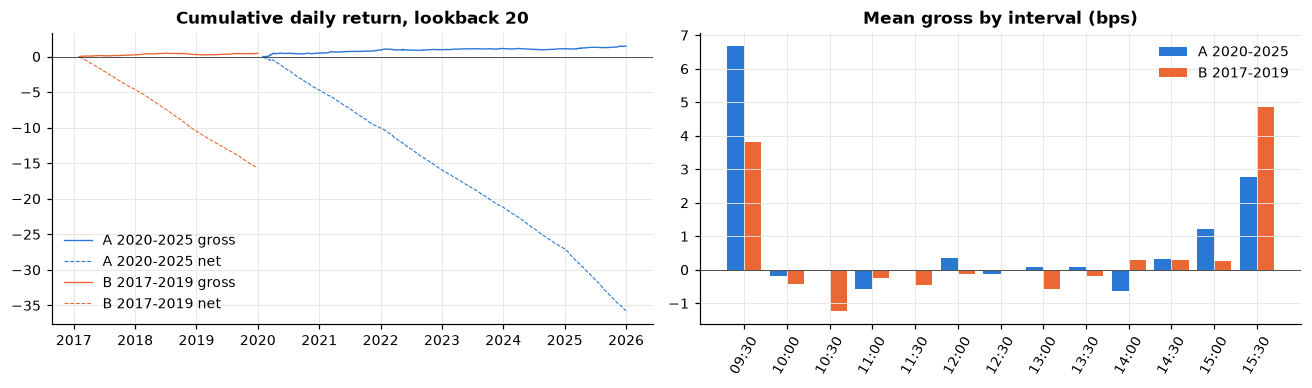

In [3]:
DAILY, TABLE, SLOTS = {}, [], {}
for name, d in DATA.items():
    for n in CFG.lookbacks_reported:
        W = p3.decile_weights(p3.same_slot_signal(d["R"], n), CFG.decile, CFG.min_names_portfolio)
        s = p3.strategy(W, d["R"], d["H"])
        day = p3.daily(s, d["days"])
        day = day.iloc[n:]                                  # first n sessions have no signal
        DAILY[(name, n)] = day
        TABLE.append({"window": name, "lookback": n, "gross_bps_day": 1e4 * day.gross.mean(), "cost_bps_day": 1e4 * day.cost.mean(),
                      "net_bps_day": 1e4 * day.net.mean(), "net2x_bps_day": 1e4 * (day.gross - 2 * day.cost).mean(),
                      "gross_bps_interval": 1e4 * day.gross.mean() / p3.PER_DAY,
                      "sharpe_gross": np.sqrt(252) * day.gross.mean() / day.gross.std(),
                      "turnover_per_day": float(np.abs(np.diff(np.vstack([np.zeros((1, W.shape[1])), W]), axis=0)).sum() / len(d["days"]))})
        if n == CFG.lookback:
            gi = s["gross"].to_numpy().reshape(-1, p3.PER_DAY)[n:]
            SLOTS[name] = pd.Series(1e4 * np.nanmean(gi, 0), index=[f"{9 + (30 + 30 * k) // 60:02d}:{(30 + 30 * k) % 60:02d}" for k in range(p3.PER_DAY)])
        del W
TABLE = pd.DataFrame(TABLE).set_index(["window", "lookback"])
TABLE.to_csv(OUT / "by_window_lookback.csv", float_format="%.5g"); pd.DataFrame(SLOTS).to_csv(OUT / "gross_by_slot_bps.csv", float_format="%.5g")
display(TABLE.round(3)); display(pd.DataFrame(SLOTS).round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for name in DATA:
    dd = DAILY[(name, CFG.lookback)]
    ax[0].plot(dd.index, dd.gross.cumsum(), color=WCOL[name], lw=0.9, label=f"{name} gross")
    ax[0].plot(dd.index, dd.net.cumsum(), color=WCOL[name], lw=0.7, ls="--", label=f"{name} net")
    ax[1].bar(np.arange(p3.PER_DAY) + (0.2 if name.startswith("B") else -0.2), SLOTS[name], width=0.4, color=WCOL[name], label=name)
ax[0].axhline(0, color="#444", lw=0.6); ax[0].legend(frameon=False); ax[0].set_title(f"Cumulative daily return, lookback {CFG.lookback}")
ax[1].set_xticks(range(p3.PER_DAY)); ax[1].set_xticklabels(list(SLOTS[next(iter(SLOTS))].index), rotation=60); ax[1].axhline(0, color="#444", lw=0.6)
ax[1].legend(frameon=False); ax[1].set_title("Mean gross by interval (bps)"); plt.tight_layout(); plt.show()

## 3. Gates

In [4]:
GATES, BOOT = {}, {}
for name in DATA:
    dd = DAILY[(name, CFG.lookback)]
    bg = {b: p1.block_bootstrap(dd.gross.to_numpy(), b, CFG.n_boot, CFG.seed, 0.05) for b in CFG.blocks}
    bn = {b: p1.block_bootstrap(dd.net.to_numpy(), b, CFG.n_boot, CFG.seed, 0.05) for b in CFG.blocks}
    BOOT[name] = {"gross": bg, "net": bn}
    GATES[name] = p3.gates_02(bg, bn, float((dd.gross - 2 * dd.cost).mean()))
    dd.to_csv(OUT / f"daily_{name.split()[0]}.csv", float_format="%.6g")
bt = pd.concat({(n, s): pd.DataFrame(v, index=["mean", "lo95", "hi95"]).T * 1e4 for n, x in BOOT.items() for s, v in x.items()})
display(bt.round(3)); display(pd.DataFrame(GATES))
VERDICT = "EDGE_CANDIDATE" if all(g["pass"] for g in GATES.values()) else "NO_EDGE"
print("verdict:", VERDICT)
summary = {"study": "P3-02", "synthetic": SYNTHETIC, "config": CFG.as_dict(), "windows": WINDOWS,
           "table": {f"{w}|{n}": v for (w, n), v in TABLE.to_dict(orient="index").items()},
           "gross_by_slot_bps": {n: s.to_dict() for n, s in SLOTS.items()},
           "bootstrap_bps": {n: {s: {str(b): [1e4 * x for x in v] for b, v in d.items()} for s, d in x.items()} for n, x in BOOT.items()},
           "gates": GATES, "verdict": VERDICT, "prospective_verdict": "PENDING_2026_HOLDOUT" if VERDICT == "EDGE_CANDIDATE" else "NOT_APPLICABLE",
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "p3": p3.P3_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir())}, indent=2))

mean     lo95     hi95
A 2020-2025 gross 10    9.896    4.364   16.116
                  20    9.896    3.755   16.927
                  40    9.896    2.723   16.652
            net   10 -242.126 -251.994 -231.707
                  20 -242.126 -255.351 -228.251
                  40 -242.126 -259.339 -225.297
B 2017-2019 gross 10    6.265    0.971   10.675
                  20    6.265   -0.002   11.082
                  40    6.265   -1.201   11.610
            net   10 -215.523 -222.224 -209.868
                  20 -215.523 -224.042 -209.170
                  40 -215.523 -226.280 -208.094

,A 2020-2025,B 2017-2019
E1_gross,True,False
E2_net,False,False
pass,False,False


verdict: NO_EDGE


136